# 01 · Incidents: Exploratory Data Analysis (EDA)

**EDA = getting to know your data before you change anything.** We answer:
- What does one row mean?
- Which values are missing, odd or wrong?
- What is the thing we want to predict, and how often does it happen?
- Which columns look related to it?

We **don't change or save any data here**. We only look and write down what needs fixing. The fixing happens in notebook 02.

**Dataset:** UCI *Incident Management Process Enriched Event Log*. These are IT helpdesk tickets from a real company's ServiceNow system (2016–2017).

**Our prediction goal:** when a ticket is opened, predict **whether it will breach its SLA** (SLA = the promised time to fix it).
The column `made_sla` tells us: `True` = fixed on time, `False` = breached.

## Setup: paths, libraries, chart style
Run this first in every notebook.

In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "data/raw/incidents"
FIG = ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

BLUE, ORANGE = "#2a78d6", "#eb6834"   # main colour, and the "bad / late / breached" colour
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12,
})

def save(fig, name):
    """Save a chart into reports/figures so you can use it in slides."""
    fig.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

print("Root:", ROOT)

Root: c:\Users\Arpita Thakur\Desktop\opsinsight 2\opsinsight 2\OpsInsight


## Step 1: Load the raw file and look at it
`pd.read_csv` reads the CSV into a **DataFrame** (a table). `low_memory=False` stops a warning about mixed column types.

In [19]:
raw = pd.read_csv(RAW / "incident_event_log.csv", low_memory=False)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (141712, 36)


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 21,29/2/2016 01:23,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 642,29/2/2016 08:53,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 804,29/2/2016 11:29,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 908,5/3/2016 12:00,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,Created by 171,29/2/2016 04:57,Updated by 746,29/2/2016 04:57,Phone,Location 165,Category 40,Subcategory 215,Symptom 471,?,2 - Medium,2 - Medium,3 - Moderate,Group 70,Resolver 89,True,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


`.dtypes` shows the type of each column. Notice the **dates are stored as text** (`object`/`str`), not as real dates. We'll have to convert them.

In [20]:
raw.dtypes

number                     object
incident_state             object
active                       bool
reassignment_count          int64
reopen_count                int64
sys_mod_count               int64
made_sla                     bool
caller_id                  object
opened_by                  object
opened_at                  object
sys_created_by             object
sys_created_at             object
sys_updated_by             object
sys_updated_at             object
contact_type               object
location                   object
category                   object
subcategory                object
u_symptom                  object
cmdb_ci                    object
impact                     object
urgency                    object
priority                   object
assignment_group           object
assigned_to                object
knowledge                    bool
u_priority_confirmation      bool
notify                     object
problem_id                 object
rfc           

## Step 2: What does one row mean?
There are ~141,000 rows, but are there 141,000 tickets? Let's count unique ticket numbers.

In [21]:
n_rows = len(raw)
n_tickets = raw["number"].nunique()
print(f"Rows: {n_rows:,}   Unique tickets: {n_tickets:,}   Avg rows per ticket: {n_rows / n_tickets:.1f}")
raw.groupby("number").size().describe()

Rows: 141,712   Unique tickets: 24,918   Avg rows per ticket: 5.7


count    24918.000000
mean         5.687134
std          3.677845
min          2.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         58.000000
dtype: float64

**Key insight:** this is an **event log**. Each row is one *update* to a ticket (created, assigned, resolved, closed...).
One ticket has many rows. Here is the full history of one ticket, sorted by its update counter `sys_mod_count`:

In [22]:
example = raw[raw["number"] == "INC0000045"].sort_values("sys_mod_count")
example[["number", "incident_state", "sys_mod_count", "reassignment_count", "assignment_group", "made_sla", "sys_updated_at"]]

,number,incident_state,sys_mod_count,reassignment_count,assignment_group,made_sla,sys_updated_at
0,INC0000045,New,0,0,Group 56,True,29/2/2016 01:23
1,INC0000045,Resolved,2,0,Group 56,True,29/2/2016 08:53
2,INC0000045,Resolved,3,0,Group 56,True,29/2/2016 11:29
3,INC0000045,Closed,4,0,Group 56,True,5/3/2016 12:00


➡ **To fix later:** for the model we need **one row per ticket**. We'll collapse the events in notebook 02.

## Step 3: Find the hidden missing values
Pandas thinks nothing is missing...

In [23]:
print("Missing according to pandas:", raw.isna().sum().sum())

Missing according to pandas: 0


...but this dataset writes missing values as a question mark `"?"`. Let's count `"?"` per column (as a % of rows):

In [24]:
question_marks = (raw == "?").mean().mul(100).round(1).sort_values(ascending=False)
question_marks[question_marks > 0]

caused_by           100.0
vendor               99.8
cmdb_ci              99.7
rfc                  99.3
problem_id           98.4
sys_created_by       37.5
sys_created_at       37.5
u_symptom            23.3
assigned_to          19.4
assignment_group     10.0
opened_by             3.4
resolved_at           2.2
closed_code           0.5
resolved_by           0.2
subcategory           0.1
location              0.1
category              0.1
dtype: float64

**What we learn:**
- `caused_by`, `vendor`, `cmdb_ci`, `rfc`, `problem_id` are **98–100% empty** → almost useless as features. We'll keep only a yes/no "has a value" flag.
- `assigned_to` and `u_symptom` are ~20% missing, `assignment_group` ~10%.

➡ **To fix later:** read the file with `na_values="?"` so pandas treats `?` as missing.

Let's reload it that way now so the rest of this EDA is correct:

In [25]:
df = pd.read_csv(RAW / "incident_event_log.csv", na_values="?", low_memory=False)
print("Missing cells now:", f"{df.isna().sum().sum():,}")

Missing cells now: 894,597


## Step 4: Look at the values inside each important column
`value_counts()` lists every distinct value and how many rows have it.

In [26]:
for col in ["incident_state", "priority", "impact", "urgency", "contact_type", "made_sla"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())


--- incident_state ---
incident_state
Active                38716
New                   36407
Resolved              25751
Closed                24985
Awaiting User Info    14642
Awaiting Vendor         707
Awaiting Problem        461
Awaiting Evidence        38
-100                      5

--- priority ---
priority
3 - Moderate    132452
4 - Low           4030
2 - High          2972
1 - Critical      2258

--- impact ---
impact
2 - Medium    134335
3 - Low         3886
1 - High        3491

--- urgency ---
urgency
2 - Medium    134094
1 - High        4020
3 - Low         3598

--- contact_type ---
contact_type
Phone             140462
Self service         995
Email                220
IVR                   18
Direct opening        17

--- made_sla ---
made_sla
True     132497
False      9215


**What we learn:**
- `incident_state` has a strange value **`-100`** on a handful of rows → a data error, drop those rows.
- `priority`, `impact`, `urgency` are text like `"2 - Medium"`. The **number** is what matters (1 = most severe). ➡ extract the number.
- Almost everything is `3 - Moderate` and `Phone`, so these columns are very **imbalanced**. That's normal in real data.

## Step 5: How many different values does each column have? ("cardinality")
Columns with a few values (like priority) are easy to use. Columns with **hundreds** of values (like `caller_id`) need special handling later.

In [27]:
df.nunique().sort_values(ascending=False).to_frame("distinct_values")

,distinct_values
sys_updated_at,50664
number,24918
opened_at,19849
resolved_at,18505
sys_created_at,11552
caller_id,5244
closed_at,2707
sys_updated_by,846
u_symptom,525
subcategory,254


## Step 6: Dates
Dates are written **day/month/year** (e.g. `29/2/2016 01:16`). If we don't say so, pandas might read `3/4/2016` as March 4th instead of April 3rd.
We give the exact format: `%d/%m/%Y %H:%M`.

In [28]:
date_cols = ["opened_at", "sys_created_at", "sys_updated_at", "resolved_at", "closed_at"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], format="%d/%m/%Y %H:%M", errors="coerce")
    print(f"{c:15s} missing={df[c].isna().sum():>6,}   from {df[c].min()}  to {df[c].max()}")

opened_at       missing=     0   from 2016-02-29 01:16:00  to 2017-02-16 14:17:00
sys_created_at  missing=53,076   from 2016-02-29 01:23:00  to 2017-01-27 16:59:00
sys_updated_at  missing=     0   from 2016-02-29 01:23:00  to 2017-02-18 15:00:00
resolved_at     missing= 3,141   from 2016-02-29 09:04:00  to 2017-02-17 00:47:00
closed_at       missing=     0   from 2016-02-29 17:47:00  to 2017-02-18 15:00:00


How many **tickets** were opened each month?

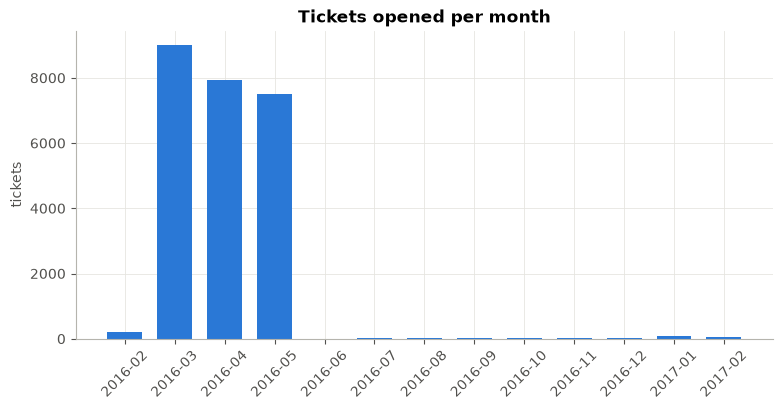

,tickets
opened_at,
2016-02,207
2016-03,8995
2016-04,7934
2016-05,7508
2016-06,5
2016-07,14
2016-08,15
2016-09,12
2016-10,16


In [29]:
opened = df.groupby("number")["opened_at"].first()
per_month = opened.dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(per_month.index.astype(str), per_month.values, color=BLUE, width=0.7)
ax.set_title("Tickets opened per month")
ax.set_ylabel("tickets")
plt.xticks(rotation=45)
save(fig, "inc_tickets_per_month")
plt.show()
per_month.to_frame("tickets")

**What we learn:** almost all tickets were opened **29 Feb – 31 May 2016**. After June there are only a few dozen per month, too few to learn from, and they would distort "how busy was the team" features.

➡ **To fix later:** keep tickets opened from 29 Feb to 31 May 2016 only.

## Step 7: Make a quick "one row per ticket" view for exploring
We sort the events by ticket and update counter, then take the **last** event of each ticket (its final state).
(We do this properly in notebook 02; this is just to explore.)

In [30]:
df = df[df["incident_state"] != "-100"]
last = df.sort_values(["number", "sys_mod_count"]).drop_duplicates("number", keep="last").set_index("number")
last["breached"] = ~last["made_sla"]
print("Tickets:", len(last))
print(f"Breach rate: {last['breached'].mean():.1%}")

Tickets: 24918
Breach rate: 36.6%


### The target: how often do tickets breach SLA?
About **1 in 3 tickets breaches**. That's a healthy balance for a model: not too rare.

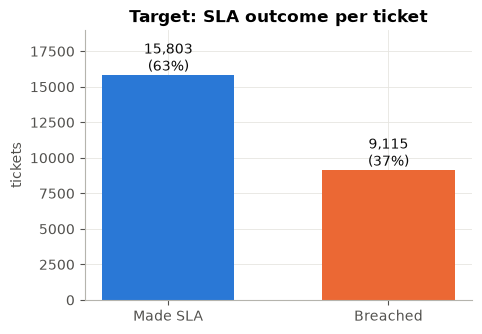

In [31]:
counts = last["breached"].map({False: "Made SLA", True: "Breached"}).value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=[BLUE, ORANGE], width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.0%})", ha="center", va="bottom", color="#0b0b0b")
ax.set_title("Target: SLA outcome per ticket")
ax.set_ylabel("tickets")
ax.set_ylim(0, counts.max() * 1.2)
save(fig, "inc_target_balance")
plt.show()

### Is the breach rate stable over time?
We look only at the main period (until end of May) and compute the breach rate per week.

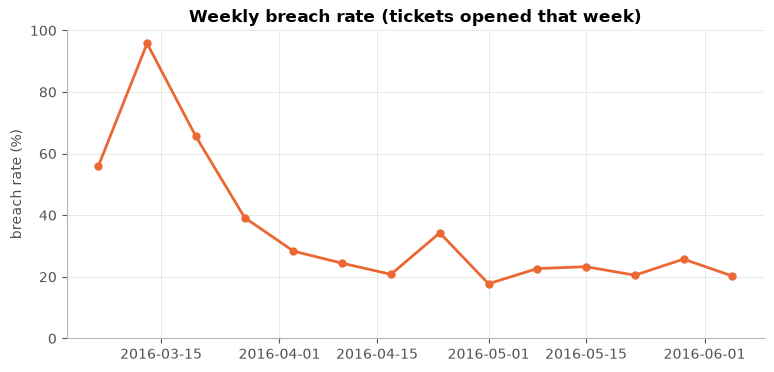

,breach_rate_%
opened_at,
2016-03-06,55.9
2016-03-13,95.8
2016-03-20,65.6
2016-03-27,39.2
2016-04-03,28.3
2016-04-10,24.4
2016-04-17,20.8
2016-04-24,34.3
2016-05-01,17.7


In [32]:
main = last[last["opened_at"] < "2016-06-01"]
weekly = main.set_index("opened_at").resample("W")["breached"].mean() * 100
fig, ax = plt.subplots()
ax.plot(weekly.index, weekly.values, color=ORANGE, linewidth=2, marker="o", markersize=5)
ax.set_title("Weekly breach rate (tickets opened that week)")
ax.set_ylabel("breach rate (%)")
ax.set_ylim(0, 100)
save(fig, "inc_weekly_breach_rate")
plt.show()
weekly.round(1).to_frame("breach_rate_%")

**What we learn:** the breach rate is **not stable**. In mid-March almost every ticket breached (probably a big outage or backlog), then it settles around 20–25% from April onwards.
This is called **drift**. It means:
- the test period (newest tickets) will have fewer breaches than the training period;
- "recent" history (last 7 days) is more useful than all-time history. We'll build both kinds of features in notebook 03.

### Does breaching change during a ticket's life?
`made_sla` is recorded on every event. Does it flip from True to False as the ticket ages?

In [33]:
flips = df.groupby("number")["made_sla"].nunique()
print(f"Tickets whose made_sla value changes during their life: {(flips > 1).sum():,} of {len(flips):,}")

Tickets whose made_sla value changes during their life: 9,114 of 24,918


**Important:** `made_sla` starts as `True` and **flips to `False` once the deadline passes**. So the true outcome is the value on the **last** event. Using the first value would be wrong.

## Step 8: What is related to breaching?
A helper function: for any column, show the breach rate and ticket count for each value.

In [34]:
def breach_by(col, data=last, min_count=50):
    t = data.groupby(col, observed=True)["breached"].agg(tickets="size", breach_rate="mean")
    t = t[t["tickets"] >= min_count]          # hide tiny groups, their rates are just noise
    t["breach_rate"] = t["breach_rate"].round(3)
    return t

breach_by("priority")

,tickets,breach_rate
priority,,
1 - Critical,270,0.981
2 - High,408,0.995
3 - Moderate,23466,0.355
4 - Low,774,0.159


Surprise: **Critical and High tickets breach almost every time (~98–99%)**, while Low tickets rarely do. Their SLA deadline is much shorter, so it's easier to miss.
Priority will be a very strong feature, but there are only ~680 Critical/High tickets, so the model mostly has to learn about the 23,000 Moderate ones.

In [35]:
breach_by("contact_type", min_count=10)

,tickets,breach_rate
contact_type,,
Email,59,0.661
Phone,24688,0.365
Self service,158,0.437


### The biggest root cause: reassignment ("ticket ping-pong")
`reassignment_count` = how many times a ticket was passed to another team.

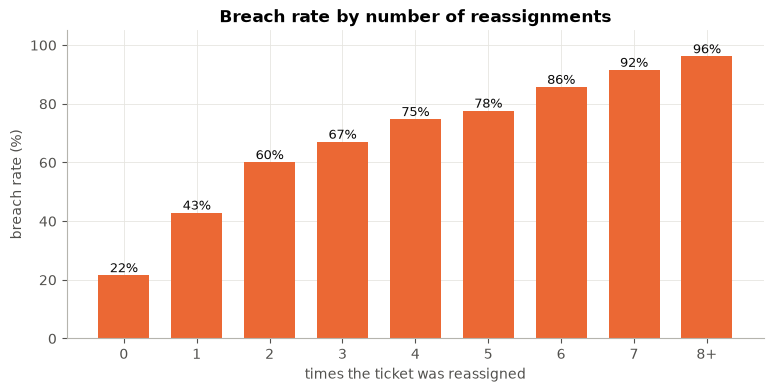

,tickets,breach_rate
reassignment_count,,
0,13549,0.216
1,6238,0.429
2,2283,0.601
3,1234,0.671
4,695,0.748
5,381,0.777
6,183,0.858
7,143,0.916
8,212,0.962


In [36]:
r = last["reassignment_count"].clip(upper=8)   # group 8+ together
rate = last.groupby(r)["breached"].mean()
size = last.groupby(r).size()
labels = [str(i) if i < 8 else "8+" for i in rate.index]

fig, ax = plt.subplots()
ax.bar(labels, rate.values * 100, color=ORANGE, width=0.7)
for i, (v, n) in enumerate(zip(rate.values, size.values)):
    ax.text(i, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=9, color="#0b0b0b")
ax.set_title("Breach rate by number of reassignments")
ax.set_xlabel("times the ticket was reassigned")
ax.set_ylabel("breach rate (%)")
ax.set_ylim(0, 105)
save(fig, "inc_breach_by_reassignment")
plt.show()
pd.DataFrame({"tickets": size, "breach_rate": rate.round(3)})

**This is your strongest story:** tickets that are never reassigned rarely breach; tickets passed around 5+ times almost always do.

⚠ **But careful, this is the most important lesson of the whole project:** we only know the *final* reassignment count **after the ticket is finished**.
If we give it to a model that predicts *at the moment the ticket is opened*, the model is "cheating" by using the future. This is called **data leakage**.
- ✅ Use it for **root-cause analysis** (explaining *why* breaches happen).
- ❌ Do NOT use it as a feature for the at-opening prediction model.

### Assignment group (which team handles it)

In [37]:
by_group = breach_by("assignment_group", min_count=200).sort_values("breach_rate", ascending=False)
print("Teams with 200+ tickets:", len(by_group))
by_group.head(10)

Teams with 200+ tickets: 23


,tickets,breach_rate
assignment_group,,
Group 10,343,0.749
Group 66,376,0.697
Group 31,205,0.683
Group 57,313,0.681
Group 72,367,0.632
Group 29,257,0.623
Group 33,201,0.612
Group 20,394,0.584
Group 25,1243,0.572


Breach rates differ a lot between teams → "which team" is a useful feature. We'll also add "how busy was that team when the ticket arrived".

### Category

In [38]:
breach_by("category", min_count=300).sort_values("breach_rate", ascending=False).head(10)

,tickets,breach_rate
category,,
Category 45,602,0.741
Category 34,501,0.665
Category 40,436,0.610
Category 61,810,0.530
Category 46,2432,0.516
Category 44,302,0.500
Category 23,1063,0.475
Category 24,640,0.473
Category 9,1155,0.408


## Step 9: How long do tickets take?
Resolution time = `resolved_at − opened_at`, in hours.

In [39]:
last["hours_to_resolve"] = (last["resolved_at"] - last["opened_at"]).dt.total_seconds() / 3600
print(last["hours_to_resolve"].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print("Negative durations (impossible):", (last["hours_to_resolve"] < 0).sum())
print("No resolved_at:", last["hours_to_resolve"].isna().sum())

count    23362.0
mean       178.2
std        532.8
min          0.0
25%          0.4
50%         22.1
75%        148.5
90%        381.5
99%       2843.4
max       8070.2
Name: hours_to_resolve, dtype: float64
Negative durations (impossible): 0
No resolved_at: 1556


The average is far bigger than the median, so a few tickets take a very long time (**right-skewed**). A log scale shows the shape better:

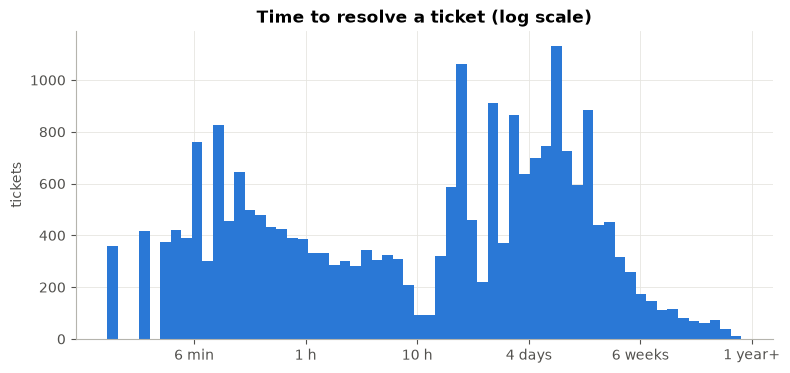

In [40]:
h = last["hours_to_resolve"].dropna()
h = h[h > 0]
fig, ax = plt.subplots()
ax.hist(np.log10(h), bins=60, color=BLUE)
ax.set_xticks([-1, 0, 1, 2, 3, 4])
ax.set_xticklabels(["6 min", "1 h", "10 h", "4 days", "6 weeks", "1 year+"])
ax.set_title("Time to resolve a ticket (log scale)")
ax.set_ylabel("tickets")
save(fig, "inc_resolution_time")
plt.show()

### Reopened tickets

In [41]:
breach_by(last["reopen_count"].clip(upper=2).rename("reopen_count"), min_count=10)

,tickets,breach_rate
reopen_count,,
0,24643,0.361
1,245,0.735
2,30,0.933


### Time of day / day of week the ticket was opened

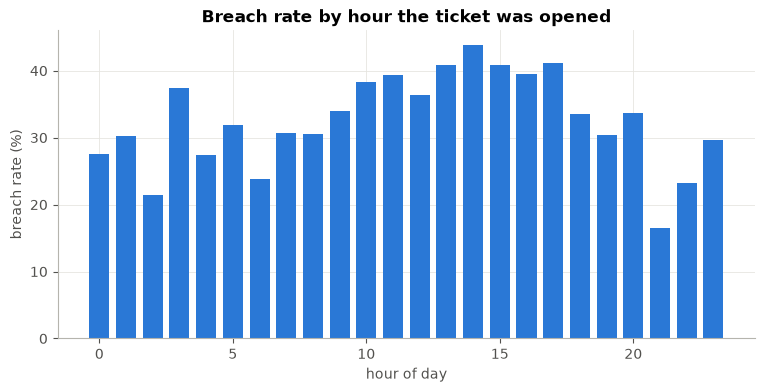

,tickets,breach_rate
open_weekday,,
Friday,3829,0.336
Monday,5947,0.355
Saturday,639,0.211
Sunday,563,0.277
Thursday,4105,0.378
Tuesday,4951,0.384
Wednesday,4884,0.404


In [42]:
last["open_hour"] = last["opened_at"].dt.hour
last["open_weekday"] = last["opened_at"].dt.day_name()
fig, ax = plt.subplots()
hr = last.groupby("open_hour")["breached"].mean() * 100
ax.bar(hr.index, hr.values, color=BLUE, width=0.75)
ax.set_title("Breach rate by hour the ticket was opened")
ax.set_xlabel("hour of day")
ax.set_ylabel("breach rate (%)")
save(fig, "inc_breach_by_hour")
plt.show()
breach_by("open_weekday")

## Step 10: Summary: what we learned and what to fix

| # | Finding | What we'll do (notebook 02 / 03) |
|---|---|---|
| 1 | Each row is an **update**, not a ticket | Collapse to one row per ticket |
| 2 | Missing values are written as `?` | Read with `na_values="?"` |
| 3 | 5 columns are 98–100% empty | Drop them, keep a "has value" flag |
| 4 | `incident_state = -100` on a few rows | Drop those rows |
| 5 | Dates are text, day/month/year | Parse with format `%d/%m/%Y %H:%M` |
| 6 | Priority/impact/urgency are text like `"2 - Medium"` | Extract the number |
| 7 | Almost all tickets are Mar–May 2016 | Keep 29 Feb – 31 May 2016 |
| 8 | `made_sla` flips to False over time | Target = `made_sla` on the **last** event |
| 9 | Final reassignment/reopen counts are known only at the end | Use for root cause only, **never** as at-opening features |
| 10 | Team, category, priority, hour all relate to breaching | Use as features, plus team workload |
| 11 | Columns with hundreds of values (caller, location) | Group rare values into "Other" |

➡ Next: **02_incidents_cleaning.ipynb**